# Exercises on Neural Networks

See below for some premade code pertaining to this weeks exercises.

## Exercise 1: My first forward pass

In this exercise you will build a basic predictive model to classify cases in the `portraits and scenes` dataset. We first carry over some code from last week's demo, and then compare with a model we put together without using the prebuild functions.

In [1]:
## Load the dataset
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, random_split, DataLoader

device = 'mps'

In [2]:
data = pd.read_csv('portraits_and_scenes.csv')
X = data[['L','C','R']].values
y = data['class'].values

X_t = torch.tensor(X, dtype=torch.float32).to(device)
y_t = torch.tensor(y, dtype=torch.long).to(device)     # classification use long

print(X_t.size(), y_t.size())
data

torch.Size([300, 3]) torch.Size([300])


,L,C,R,class
0,0.563286,1.000000,0.368785,0
1,0.251172,0.552383,0.529757,0
2,0.032279,0.276465,0.124215,0
3,0.040153,0.730927,0.627702,0
4,0.198425,0.290947,0.235601,0
...,...,...,...,...
295,0.222759,0.861686,0.362825,1
296,0.419330,0.747285,0.255173,1
297,0.697766,0.380347,0.737845,1
298,0.981358,0.635208,0.518663,1


In [3]:
## Split the dataset into training and testing sets
dataset = TensorDataset(X_t, y_t)

g = torch.Generator().manual_seed(42)
train_set, val_set, test_set = random_split(dataset, [0.7, 0.15, 0.15], generator=g)
# it might have to take sklearn "stratify=y" for use to keep the portion of these 2 category

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=len(val_set))
test_loader  = DataLoader(test_set, batch_size=len(test_set))

In [4]:
for x_batch, y_batch in train_loader:
    print(x_batch.size(), y_batch.size())   # 例如 torch.Size([64, 3]) torch.Size([64])
    break

torch.Size([32, 3]) torch.Size([32])


In [5]:
## Copy over the `SomeModel` class from last week, adjust it so it works for the new dataset

class SomeModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.a_model_definition = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.a_model_definition(x) # Passes data through the model

In [6]:
## Copy over the training loop from the intro_to_pytorch notebook adjust as needed.

def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().sum() / y_true.size(0) * 100

def advance_evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * y.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n * 100

model = SomeModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


for epoch in range(3000):
    model.train()
    for x_batch, y_batch in train_loader:  # --> my own adjustment here, turn it into mini-batch
        logits = model(x_batch)
        loss = loss_fn(logits, y_batch)

        optimizer.zero_grad()  # Zero gradients
        loss.backward()  # Backpropagation
        optimizer.step()  # Update weights # 這三者都是一起出現的

    if epoch % 100 == 0:
        train_loss, train_acc = advance_evaluate(model, train_loader)
        val_loss, val_acc = advance_evaluate(model, val_loader)
        print(f"Epoch {epoch:<4} | train loss={train_loss:.4f} acc={train_acc:.2f} "
              f"| val loss={val_loss:.4f} acc={val_acc:.2f}")

Epoch 0    | train loss=0.6870 acc=51.90 | val loss=0.6848 acc=51.11
Epoch 100  | train loss=0.2406 acc=89.52 | val loss=0.2115 acc=86.67
Epoch 200  | train loss=0.2323 acc=89.52 | val loss=0.2082 acc=88.89
Epoch 300  | train loss=0.2189 acc=90.48 | val loss=0.1944 acc=86.67
Epoch 400  | train loss=0.2077 acc=91.90 | val loss=0.1911 acc=86.67
Epoch 500  | train loss=0.1988 acc=93.33 | val loss=0.1827 acc=88.89
Epoch 600  | train loss=0.1921 acc=93.81 | val loss=0.1790 acc=88.89
Epoch 700  | train loss=0.1863 acc=93.81 | val loss=0.2196 acc=86.67
Epoch 800  | train loss=0.1830 acc=94.29 | val loss=0.1953 acc=86.67
Epoch 900  | train loss=0.1786 acc=94.29 | val loss=0.2038 acc=86.67
Epoch 1000 | train loss=0.1752 acc=94.76 | val loss=0.2378 acc=86.67
Epoch 1100 | train loss=0.1720 acc=94.29 | val loss=0.2411 acc=86.67
Epoch 1200 | train loss=0.1689 acc=94.29 | val loss=0.2556 acc=86.67
Epoch 1300 | train loss=0.1658 acc=94.76 | val loss=0.2813 acc=86.67
Epoch 1400 | train loss=0.1617 acc

In [ ]:
## Evaluation
# X_test, y_test = X_t[test_set.indices], y_t[test_set.indices] # no need this annymore
val_loss, val_acc = advance_evaluate(model, test_loader)
print(f"test loss={val_loss:.4f} test acc={val_acc:.2f} ")


test loss=1.9179 test acc=82.22 


In [8]:
## Implement your own two-layer fully connected neural network without the use of the torch.nn modules.

class ManualModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.w1, self.b1 = nn.Parameter(torch.randn(3,64) * 0.1), nn.Parameter(torch.zeros(64))
        self.w2, self.b2 = nn.Parameter(torch.randn(64,3) * 0.1), nn.Parameter(torch.zeros(3))
        
    def forward(self, x):
        x = torch.clamp(x @ self.w1 + self.b1, min=0)
        x = torch.clamp(x @ self.w2 + self.b2, min=0)
        return x
    

After implementing the manual model go back up and switch the model to `ManualModel` instead of `SomeModel` to see how it performs.

## Exercise 2: Training loop
In this exercise we will try to build a model for a more complex dataset, namely the well known MNIST dataset of handwritten digits. We will use some code from the PyTorch guide to get started, see [PyTorch data tutorial](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html) and [PyTorch model tutorial](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html).

First step is getting the dataset. Review the tutorial and finish the missing codebits. 

In [9]:
## Import torchvision and download the MNIST dataset
from torchvision import datasets
from torchvision.transforms import ToTensor


training_data = datasets.MNIST(
    root="data",          # 資料存放的資料夾
    train=True,           # True = 訓練集
    download=True,        # 本機沒有就自動下載
    transform=ToTensor(), # 讀出來時把圖片轉成 tensor
)

test_data = datasets.MNIST(
    root="data",
    train=False,          # False = 測試集
    download=True,
    transform=ToTensor(),
)

The dataset will be downloaded as a `torch.dataset` object. Sometimes it can be useful to inspect unknown objects to see what methods and attributes they have. You can do this using the `dir()` function. For example, to see the methods and attributes of the `training_data` object, you can run:

In [10]:
print([attr for attr in dir(training_data) if not attr.startswith('_')])

['class_to_idx', 'classes', 'data', 'download', 'extra_repr', 'mirrors', 'processed_folder', 'raw_folder', 'resources', 'root', 'target_transform', 'targets', 'test_data', 'test_file', 'test_labels', 'train', 'train_data', 'train_labels', 'training_file', 'transform', 'transforms']


The string formatter `if not attr.startswith('_')` is used to filter out hidden attributes (those starting with an underscore). This can help you focus on the most relevant information about the object. 

Particularly, noteworthy elements for the purposes of this exercise are the `data` and `targets` attributes, which contain the actual image data and their corresponding labels. 

In [11]:
## Filter the dataset to only include digits 1 and 7

# [Hint: find the indexes where targets are either 1 or 7, then use slicing of the labels and the data to get those those]

idx = (training_data.targets == 1) + (training_data.targets == 7)
filtered_data = (training_data.data[idx].float() / 255).to(device)
filtered_labels = (training_data.targets[idx] == 1).long().to(device)

# # repeat for the test data
idx = (test_data.targets == 1) + (test_data.targets == 7)
filtered_test_data = (test_data.data[idx].float() / 255).to(device)
filtered_test_labels = (test_data.targets[idx] == 1).long().to(device)

In [12]:
print(f"Training data size: {filtered_data.size()}")
print(f"Test data size: {filtered_test_data.size()}")

Training data size: torch.Size([13007, 28, 28])
Test data size: torch.Size([2163, 28, 28])


In [13]:
train_loader = DataLoader(TensorDataset(filtered_data, filtered_labels), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(filtered_test_data, filtered_test_labels), batch_size=64)

Next we will take the model from the second tutorial and modify it to our needs. [Hint: check the last linear layer and the number of classes in the dataset]

Notice that the way this model handles images is by flattening them into a single vector. This is not the best way to handle complex images, but it is a good starting point at this stage.

In [14]:
## Copy over the NeuralNetwork model from the PyTorch tutorial

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 2),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


In [15]:
## Copy over the training loop, adjust it for the new data, and add batch training. 
def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().sum() / y_true.size(0) * 100

model = NeuralNetwork().to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.train()
for epoch in range(100):
    for x_batch, y_batch in train_loader:
        logits = model(x_batch)
        loss = loss_fn(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch % 100 == 0:
        pred = logits.argmax(dim=1)
        acc = accuracy(y_batch, pred)
        print(f"Epoch {epoch:<4} | loss={loss.item():.4f} | accuracy={acc.item():.2f}")



Epoch 0    | loss=0.0011 | accuracy=100.00


KeyboardInterrupt: 

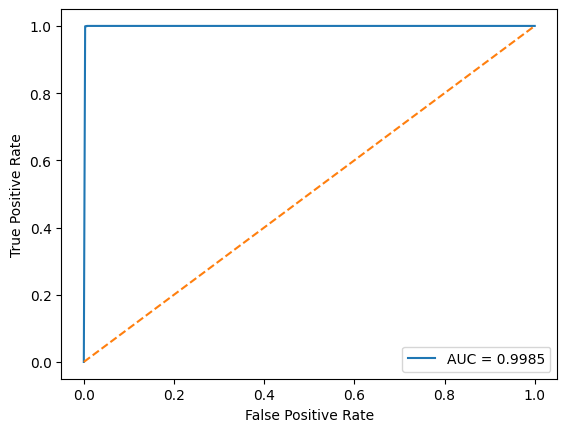

In [ ]:
## Draw a roc curve for the model on the test data.

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# y_true = y_test.detach().cpu().numpy()
# y_pred = model(X_test).squeeze().detach().cpu().numpy()

### Your code here ###




y_true = filtered_test_labels.cpu().numpy()
y_pred = torch.softmax(model(filtered_test_data), dim=1)[:, 1].detach().cpu().numpy()

fpr, tpr, _ = roc_curve(y_true, y_pred)
plt.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.4f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## Exercise 3: Residual Neural Networks

ResNet is a famous architecture/ sub-architecture, paticularly in computer vision, however outside it is still a fairly powerful design element for preventing vanishing gradients in deeper networks.

This exercise aims to show the flexibility of torch modules while implementing a simple residual network block.

In [ ]:
## Complete the following module
import torch
from torch import nn

class ResnetBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(8, 8)
        self.layer2 = nn.Linear(8, 8)   

    def forward(self, x):
        ### Your code here ###


In [ ]:
## Copy the overkill model over and make sure the dimensions work out for your ResNetBlock.



In [ ]:
## Load the concentric dataset
import pandas as pd

data = pd.read_csv('concentric.csv')

X_train = data[['X0','X1']].values
y_train = data['label'].values

X_train = torch.from_numpy(X_train).float()
y_train = torch.from_numpy(y_train).float()

In [ ]:
## Copy the training loop (batch training or basic variant) here:




In [ ]:
# Use torchviz to sketch out the computational graph of the model.
from torchviz import make_dot

make_dot(model(X_train), params=dict(
    list(model.named_parameters()))
    )